In [1]:

from google.colab import files
uploaded = files.upload()


Saving retail_sales_dataset_custom.csv to retail_sales_dataset_custom.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (1220, 12)


,Date,Store,Product,Category,Price,Quantity,Payment_Method,City,Customer_Age,Customer_Gender,Weekly_Sales,Holiday_Flag
0,2023-02-08,Store B,Vacuum,Home & Kitchen,1509.76,NaN,Cash,New York,43.0,Female,3727.97,0
1,2023-06-04,Store D,Football,Sports,813.59,7.0,Online Payment,Chicago,19.0,Male,5997.06,0
2,2023-01-10,Store A,Football,Sports,504.67,6.0,Cash,Los Angeles,NaN,Male,3608.06,0
3,2022-02-14,Store A,Basketball,Sports,389.39,4.0,Debit Card,Chicago,62.0,Female,1431.62,0
4,2022-10-08,Store C,Microwave,Home & Kitchen,324.65,NaN,Cash,Los Angeles,31.0,Male,2512.16,0


['Date', 'Store', 'Product', 'Category', 'Price', 'Quantity', 'Payment_Method', 'City', 'Customer_Age', 'Customer_Gender', 'Weekly_Sales', 'Holiday_Flag']


In [3]:

# Create two classes using the median Weekly_Sales
median_sales = df["Weekly_Sales"].median()

df["Sales_Category"] = np.where(
    df["Weekly_Sales"] >= median_sales,
    "High Sales",
    "Low Sales"
)

# Remove target-related and date columns from inputs
X = df.drop(
    columns=["Weekly_Sales", "Sales_Category", "Date"]
)
y = df["Sales_Category"]

print("Sales categories:")
print(y.value_counts())
print("\nFeatures and target prepared!")


Sales categories:
Sales_Category
Low Sales     610
High Sales    610
Name: count, dtype: int64

Features and target prepared!


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices into arrays if needed
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()

print("Data preprocessing completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Data preprocessing completed!
Training samples: 976
Testing samples: 244


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices into arrays if needed
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()

print("Data preprocessing completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Data preprocessing completed!
Training samples: 976
Testing samples: 244


In [6]:

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_2d = pca.fit_transform(X_train_processed)
X_test_2d = pca.transform(X_test_processed)

# Encode High Sales as 0 and Low Sales as 1
label_map = {"High Sales": 0, "Low Sales": 1}

y_train_encoded = y_train.map(label_map).to_numpy()
y_test_encoded = y_test.map(label_map).to_numpy()

print("PCA completed!")
print("Explained variance:", pca.explained_variance_ratio_.sum())


PCA completed!
Explained variance: 0.24861719873164453


In [7]:

from sklearn.svm import SVC

# Linear SVM
svm_linear = SVC(kernel="linear", C=1.0)
svm_linear.fit(X_train_2d, y_train_encoded)

# Non-linear SVM
svm_nonlinear = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)
svm_nonlinear.fit(X_train_2d, y_train_encoded)

print("Linear SVM trained successfully!")
print("Non-linear SVM trained successfully!")


Linear SVM trained successfully!
Non-linear SVM trained successfully!


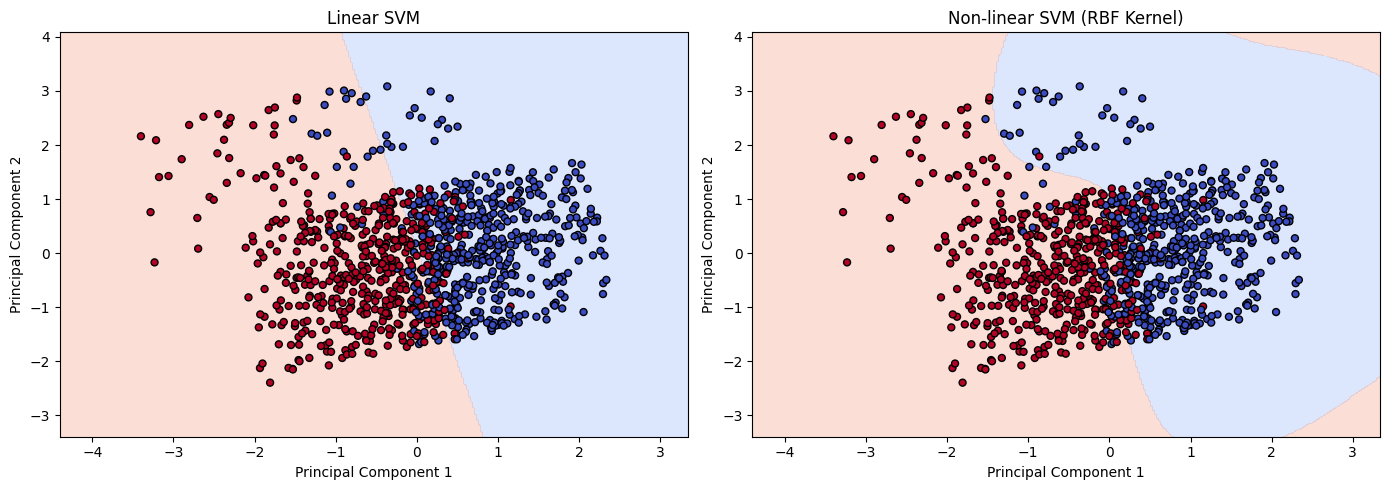

In [8]:

# Create a grid for plotting the decision boundaries
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (svm_linear, "Linear SVM"),
    (svm_nonlinear, "Non-linear SVM (RBF Kernel)")
]

for ax, (svm, title) in zip(axes, models):
    Z = svm.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        cmap="coolwarm",
        alpha=0.3
    )

    ax.scatter(
        X_train_2d[:, 0],
        X_train_2d[:, 1],
        c=y_train_encoded,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()


In [9]:

from sklearn.metrics import accuracy_score

for svm, name in models:
    predictions = svm.predict(X_test_2d)
    accuracy = accuracy_score(y_test_encoded, predictions)
    print(f"{name} Accuracy: {accuracy * 100:.2f}%")


Linear SVM Accuracy: 84.43%
Non-linear SVM (RBF Kernel) Accuracy: 86.48%
